In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
df=pd.read_csv('C:/Users/moham/Downloads/used_cars_10000.csv')

In [3]:
df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Yes,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Yes,"$34,999"


In [4]:
df.tail()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
9995,Mitsubishi,Lancer GTS,2009,"186,100 mi.",Gasoline,168.0HP 2.4L 4 Cylinder Engine Gasoline Fuel,CVT Transmission,Orange,Gray,At least 1 accident or damage reported,Yes,"$5,360"
9996,BMW,325 xi,2006,"144,500 mi.",Gasoline,215.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,6-Speed A/T,Silver,Black,None reported,Yes,"$3,970"
9997,Porsche,Cayenne Turbo,2020,"41,600 mi.",Gasoline,4.0L V8 32V GDI DOHC Twin Turbo,8-Speed Automatic,Quartzite Grey Metallic,Black,None reported,Yes,"$90,450"
9998,Jeep,Wrangler Unlimited Freedom Edition,2013,"51,600 mi.",Gasoline,285.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,A/T,Green,Black,None reported,Yes,"$36,300"
9999,Lamborghini,Murcielago Base,2006,"9,700 mi.",Gasoline,571.0HP 6.2L 12 Cylinder Engine Gasoline Fuel,A/T,Red,Black,None reported,Yes,"$270,730"


In [5]:
df['price'] = df['price'].str.replace('$', '', regex=False)
df['price'] = df['price'].str.replace(',', '', regex=False)
df['price'] = pd.to_numeric(df['price'])

In [6]:
df.rename(columns={"milage":"km_drive"},inplace=True)

In [7]:
df['km_drive'] = df['km_drive'].str.replace('mi.', '', regex=False)
df['km_drive'] = df['km_drive'].str.replace(',', '', regex=False)
df['km_drive'] = pd.to_numeric(df['km_drive'])

In [8]:
df.shape

(10000, 12)

In [9]:
df.nunique()

brand             57
model           1898
model_year        36
km_drive        3869
fuel_type          7
engine          1146
transmission      62
ext_col          319
int_col          156
accident           2
clean_title        1
price           5382
dtype: int64

In [10]:
df.isnull().sum()

brand           0
model           0
model_year      0
km_drive        0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64

In [11]:
df.describe()

,model_year,km_drive,price
count,10000.0000,10000.000000,1.000000e+04
mean,2015.5043,65020.333900,4.480770e+04
std,6.0377,52264.090807,8.066756e+04
min,1974.0000,100.000000,2.000000e+03
25%,2012.0000,23200.000000,1.727750e+04
50%,2017.0000,53500.000000,3.107500e+04
75%,2020.0000,94608.500000,4.950500e+04
max,2025.0000,406200.000000,3.131230e+06


<Axes: xlabel='km_drive'>

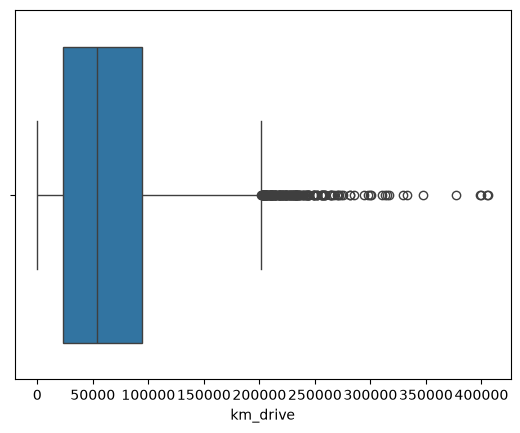

In [12]:
sns.boxplot(x='km_drive',data=df)

<Axes: xlabel='price'>

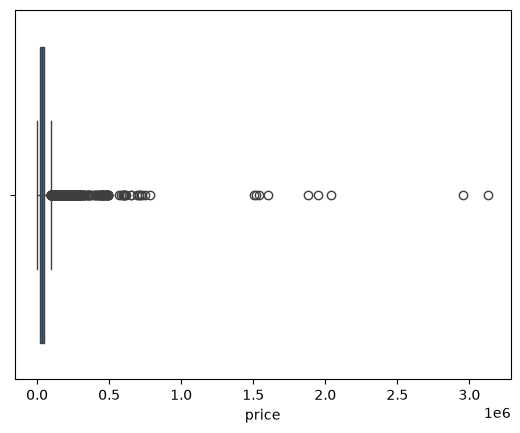

In [13]:
sns.boxplot(x='price',data=df)

In [14]:
corr = df.corr(numeric_only=True)
corr

,model_year,km_drive,price
model_year,1.000000,-0.620956,0.196773
km_drive,-0.620956,1.000000,-0.303205
price,0.196773,-0.303205,1.000000


In [15]:
from scipy.stats import f_oneway
target = 'price'
categorical_columns = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.drop(target, errors='ignore')
anova_results = []
for col in categorical_columns:
    temp = df[[col, target]].dropna()
    groups = [
        group[target].values
        for _, group in temp.groupby(col, observed=True)
        if len(group) > 1
    ]
    if len(groups) >= 2:
        f_stat, p_value = f_oneway(*groups)
        anova_results.append({
            'Feature': col,
            'F_Statistic': f_stat,
            'P_Value': p_value,
            'Relationship': (
                'Significant' if p_value < 0.05
                else 'Not Significant'
            )
        })
anova_df = pd.DataFrame(anova_results)
display(anova_df.sort_values('P_Value'))

C:\Users\moham\AppData\Local\Temp\ipykernel_12996\3913696883.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,Feature,F_Statistic,P_Value,Relationship
0,brand,115.008647,0.000000e+00,Significant
1,model,15.043737,0.000000e+00,Significant
3,engine,20.788607,0.000000e+00,Significant
4,transmission,28.919265,0.000000e+00,Significant
6,int_col,12.480261,8.779387e-234,Significant
5,ext_col,4.730139,1.004560e-122,Significant
7,accident,141.919285,1.679791e-32,Significant
2,fuel_type,5.456190,1.202773e-05,Significant


In [16]:
import pandas as pd
import numpy as np
from scipy.stats import f_oneway
target = 'price'
# Select categorical columns
categorical_columns = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.drop(target, errors='ignore')
anova_results = []
for col in categorical_columns:
    # Remove missing values from feature and target
    temp = df[[col, target]].dropna()
    # Create groups for each category
    groups = [
        group[target].values
        for _, group in temp.groupby(col, observed=True)
        if len(group) > 1
    ]
    # Check whether at least two valid groups exist
    if len(groups) < 2:
        continue
    # Perform ANOVA test
    f_stat, p_value = f_oneway(*groups)
    anova_results.append({
        'Feature': col,
        'F_Statistic': f_stat,
        'P_Value': p_value,
        'Relationship': (
            'Significant' if p_value < 0.05
            else 'Not Significant'
        )
    })
# Display results safely
anova_df = pd.DataFrame(
    anova_results,
    columns=[
        'Feature', 'F_Statistic',
        'P_Value', 'Relationship'
    ]
)
if not anova_df.empty:
    display(anova_df.sort_values(by='P_Value'))
else:
    print("No valid ANOVA results found.")
    print("Check the data types of your columns:")
    print(df.dtypes)

C:\Users\moham\AppData\Local\Temp\ipykernel_12996\3229767111.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,Feature,F_Statistic,P_Value,Relationship
0,brand,115.008647,0.000000e+00,Significant
1,model,15.043737,0.000000e+00,Significant
3,engine,20.788607,0.000000e+00,Significant
4,transmission,28.919265,0.000000e+00,Significant
6,int_col,12.480261,8.779387e-234,Significant
5,ext_col,4.730139,1.004560e-122,Significant
7,accident,141.919285,1.679791e-32,Significant
2,fuel_type,5.456190,1.202773e-05,Significant


In [17]:
df.drop(columns=['model_year'],inplace=True)

In [18]:
df

,brand,model,km_drive,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,Yes,54598
3,INFINITI,Q50 Hybrid Sport,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,Yes,34999
...,...,...,...,...,...,...,...,...,...,...,...
9995,Mitsubishi,Lancer GTS,186100,Gasoline,168.0HP 2.4L 4 Cylinder Engine Gasoline Fuel,CVT Transmission,Orange,Gray,At least 1 accident or damage reported,Yes,5360
9996,BMW,325 xi,144500,Gasoline,215.0HP 3.0L Straight 6 Cylinder Engine Gasoli...,6-Speed A/T,Silver,Black,None reported,Yes,3970
9997,Porsche,Cayenne Turbo,41600,Gasoline,4.0L V8 32V GDI DOHC Twin Turbo,8-Speed Automatic,Quartzite Grey Metallic,Black,None reported,Yes,90450
9998,Jeep,Wrangler Unlimited Freedom Edition,51600,Gasoline,285.0HP 3.6L V6 Cylinder Engine Gasoline Fuel,A/T,Green,Black,None reported,Yes,36300


In [19]:
from sklearn.preprocessing import LabelEncoder
Label = LabelEncoder()
df["brand"]=Label.fit_transform(df["brand"])
df["model"]=Label.fit_transform(df["model"])
df["engine"]=Label.fit_transform(df["engine"])
df["transmission"]=Label.fit_transform(df["transmission"])
df["fuel_type"]=Label.fit_transform(df["fuel_type"])
df["int_col"]=Label.fit_transform(df["int_col"])
df["accident"]=Label.fit_transform(df["accident"])
df["ext_col"]=Label.fit_transform(df["ext_col"])
df["clean_title"]=Label.fit_transform(df["clean_title"])

In [20]:
df.head()

,brand,model,km_drive,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,14,1743,51000,1,581,16,29,14,0,0,10300
1,19,1182,34742,2,566,32,185,71,0,0,38005
2,27,1325,22372,2,541,40,38,14,1,0,54598
3,20,1242,88900,3,724,23,29,14,1,0,15500
4,3,1225,9835,2,200,32,120,14,1,0,34999


In [21]:
x=df.drop('price',axis=1)
y = df['price']
x

,brand,model,km_drive,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
0,14,1743,51000,1,581,16,29,14,0,0
1,19,1182,34742,2,566,32,185,71,0,0
2,27,1325,22372,2,541,40,38,14,1,0
3,20,1242,88900,3,724,23,29,14,1,0
4,3,1225,9835,2,200,32,120,14,1,0
...,...,...,...,...,...,...,...,...,...,...
9995,38,945,186100,2,104,50,205,71,0,0
9996,4,42,144500,2,284,16,263,14,1,0
9997,43,431,41600,2,815,32,230,14,1,0
9998,22,1774,51600,2,468,38,129,14,1,0


In [22]:
y

0        10300
1        38005
2        54598
3        15500
4        34999
         ...  
9995      5360
9996      3970
9997     90450
9998     36300
9999    270730
Name: price, Length: 10000, dtype: int64

In [23]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [24]:
x_train

,brand,model,km_drive,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
9254,4,47,62600,2,300,53,234,14,1,0
1561,9,1574,18860,0,914,2,38,71,1,0
1670,14,675,72128,1,1064,17,304,32,1,0
6087,19,584,31000,2,63,16,128,71,0,0
6669,39,1863,83800,2,398,38,29,71,1,0
...,...,...,...,...,...,...,...,...,...,...
5734,9,597,93100,2,403,16,29,31,0,0
5191,39,1752,174900,2,35,38,29,155,1,0
5390,36,1491,114600,2,890,59,29,14,0,0
860,38,1175,131193,2,211,41,29,14,1,0


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
X = df.drop('price', axis=1)
y = df['price']
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
num_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns
scaler = MinMaxScaler()
x_train[num_cols] = scaler.fit_transform(X_train[num_cols])
x_test[num_cols] = scaler.transform(X_test[num_cols])

In [26]:
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [27]:
#import the model
#training (x_train,y_train)
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [28]:
#training
model.fit(x_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 13584.24, -3641.67,-153946.42,..., 13626.05, 3054.65, 0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.513e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](10,)","[39.12,31.86,26.91,...,10.53, 8.99, 0. ]"


In [29]:
x_pred=model.predict(x_train_scaled)

In [30]:
from sklearn.metrics import r2_score
train_acc = r2_score(x_pred,y_train)
print("training accuracy is ",train_acc)

training accuracy is  -5.370069770055326


In [31]:
y_pred=model.predict(x_test_scaled)

In [32]:
from sklearn.metrics import r2_score
test_r2 = r2_score(y_test,y_pred)
print("testing accuracy is ",test_r2)

testing accuracy is  0.28117231810815013


In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(mae)
print(mse)

23265.804524974905
1963908835.4388175


In [34]:
from sklearn.neighbors import KNeighborsRegressor
model=KNeighborsRegressor(n_neighbors= 5, p= 1, weights= 'distance')

In [35]:
model.fit(x_train_scaled,y_train)

,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'distance'
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",1
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'ma...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [36]:
x_pred=model.predict(x_train_scaled)

In [37]:
from sklearn.metrics import r2_score
train_acc = r2_score(x_pred,y_train)
print("training accuracy is ",train_acc)

training accuracy is  0.9998854118792365


In [38]:
y_pred=model.predict(x_test_scaled)

In [39]:
from sklearn.metrics import r2_score
test_r2 = r2_score(y_test,y_pred)
print("testing accuracy is ",test_r2)

testing accuracy is  0.9744578163942077


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(mae)
print(mse)

3272.434265936023
69783790.08414853


In [41]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score
# Hyperparameters
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11,12],
    'weights': ['uniform', 'distance'],
    'p': [1, 2,3]
}
# Create model
grid_search = GridSearchCV(
    KNeighborsRegressor(),
    param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
# Train model
grid_search.fit(x_train_scaled, y_train)
# Best model
knn_model = grid_search.best_estimator_
# Predictions
y_train_pred = knn_model.predict(x_train_scaled)
y_test_pred = knn_model.predict(x_test_scaled)
# Results
print("Best Parameters:", grid_search.best_params_)
print("Train R2 Score:", r2_score(y_train, y_train_pred))
print("Test R2 Score:", r2_score(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

Best Parameters: {'n_neighbors': 3, 'p': 1, 'weights': 'distance'}
Train R2 Score: 0.9998854250081695
Test R2 Score: 0.9625592678284041
MAE: 3302.8095899232285
RMSE: 10113.941372238032


In [42]:
#svr
from sklearn.svm import SVR
model=SVR()

In [43]:
model.fit(x_train_scaled,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [44]:
x_pred=model.predict(x_train_scaled)

In [45]:
from sklearn.metrics import r2_score
acc = r2_score(y_train,x_pred)
acc

-0.025145434180107396

In [46]:
y_pred=model.predict(x_test_scaled)

In [47]:
from sklearn.metrics import r2_score
test_r2 = r2_score(y_test,y_pred)
print("testing accuracy is ",test_r2)

testing accuracy is  -0.045170663914065656


In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(mae)
print(mse)

25568.696380907662
2855510372.1104503


In [ ]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
# Create pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVR())
])
# Define hyperparameters
param_grid = {
    'svm__kernel': ['rbf', 'linear', 'poly'],
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 'auto'],
    'svm__epsilon': [0.01, 0.1, 0.2]
}
# GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
# Train and find the best parameters
grid_search.fit(x_train, y_train)
# Best parameters
print("Best Parameters:", grid_search.best_params_)
# Best model
best_svm = grid_search.best_estimator_
# Prediction
y_pred = best_svm.predict(x_test)
# Evaluation
print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

In [ ]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(criterion= 'squared_error', max_depth= 10, min_samples_leaf= 2, min_samples_split = 5)

In [ ]:
model.fit(x_train, y_train)

In [ ]:
x_pred=model.predict(x_train)

In [ ]:
from sklearn.metrics import r2_score
acc = r2_score(y_train,x_pred)
acc

In [ ]:
y_pred=model.predict(x_test)

In [ ]:
from sklearn.metrics import r2_score
acc = r2_score(y_test,y_pred)
acc

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(mae)
print(mse)

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
model = DecisionTreeRegressor(random_state=42)
params = {
    'max_depth': [3, 5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
 'criterion': ['squared_error', 'absolute_error']
}
grid = GridSearchCV(
    model,
    params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid.fit(x_train, y_train)
print("Best Parameters:", grid.best_params_)
print("Best Model:", grid.best_estimator_)
best_model = grid.best_estimator_
print("Train Accuracy:", best_model.score(x_train, y_train))
print("Test Accuracy:", best_model.score(x_test, y_test))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(max_depth=20, min_samples_leaf= 1, min_samples_split=2, n_estimators= 200
)

In [ ]:
model.fit(x_train, y_train)

In [ ]:
x_pred=model.predict(x_train)

In [ ]:
from sklearn.metrics import r2_score
acc = r2_score(y_train,x_pred)
acc

In [ ]:
y_pred=model.predict(x_test)

In [ ]:
from sklearn.metrics import r2_score
acc = r2_score(y_test,y_pred)
acc

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
print(mae)
print(mse)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
# Create the model
rf = RandomForestRegressor(random_state=42)
# Hyperparameters
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
# Hyperparameter tuning
grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(x_train, y_train)
# Best model
rf_model = grid_search.best_estimator_
# Predictions
y_train_pred = rf_model.predict(x_train)
y_test_pred = rf_model.predict(x_test)
# Evaluation
print("Best Parameters:", grid_search.best_params_)
print("Training R2 Score:", r2_score(y_train, y_train_pred))
print("Testing R2 Score:", r2_score(y_test, y_test_pred))
print("MAE:", mean_absolute_error(y_test, y_test_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred)))